In [42]:

import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output
import time
import pandas as pd
import numpy as np

print("OS Scheduling Visualizer")
print("Libraries imported successfully!")


OS Scheduling Visualizer
Libraries imported successfully!


In [43]:

# ==========================================
# DISK SCHEDULING ALGORITHMS
# ==========================================

def calculate_movement(sequence):
    """Calculate total disk head movement."""
    return sum(abs(sequence[i] - sequence[i-1])
               for i in range(1, len(sequence)))


# 1. FCFS - First Come First Serve
def fcfs(requests, head):
    sequence = [head] + requests
    return sequence, calculate_movement(sequence)


# 2. SSTF - Shortest Seek Time First
def sstf(requests, head):
    remaining = requests.copy()
    sequence = [head]
    current = head

    while remaining:
        nearest = min(remaining, key=lambda x: abs(x-current))
        sequence.append(nearest)
        remaining.remove(nearest)
        current = nearest

    return sequence, calculate_movement(sequence)


# 3. SCAN
def scan(requests, head, disk_size, direction):
    left = sorted([r for r in requests if r < head], reverse=True)
    right = sorted([r for r in requests if r >= head])

    sequence = [head]

    if direction == "right":
        sequence += right
        if left:
            if sequence[-1] != disk_size - 1:
                sequence.append(disk_size - 1)
            sequence += left
    else:
        sequence += left
        if right:
            if sequence[-1] != 0:
                sequence.append(0)
            sequence += right

    return sequence, calculate_movement(sequence)



def cscan(requests, head, disk_size, direction):
    left = sorted([r for r in requests if r < head])
    right = sorted([r for r in requests if r >= head])

    sequence = [head]

    if direction == "right":
        sequence += right
        if left:
            if sequence[-1] != disk_size - 1:
                sequence.append(disk_size - 1)
            sequence.append(0)
            sequence += left

    else:
        sequence += left[::-1]
        if right:
            if sequence[-1] != 0:
                sequence.append(0)
            sequence.append(disk_size - 1)
            sequence += right[::-1]

    return sequence, calculate_movement(sequence)



# 5. LOOK
def look(requests, head, direction):
    left = sorted([r for r in requests if r < head], reverse=True)
    right = sorted([r for r in requests if r >= head])

    sequence = [head]

    if direction == "right":
        sequence += right + left
    else:
        sequence += left + right

    return sequence, calculate_movement(sequence)


print("All five disk scheduling algorithms are ready!")


All five disk scheduling algorithms are ready!


In [44]:

# Test input from the assignment

disk_size = 200
head = 50
requests = [82, 170, 43, 140, 24, 16, 190]
direction = "right"

# Run all algorithms
results = {}

results["FCFS"] = fcfs(requests, head)
results["SSTF"] = sstf(requests, head)
results["SCAN"] = scan(requests, head, disk_size, direction)
results["C-SCAN"] = cscan(requests, head, disk_size, direction)
results["LOOK"] = look(requests, head, direction)

# Display results
for name, (sequence, movement) in results.items():
    print("\nAlgorithm:", name)
    print("Head sequence:", sequence)
    print("Total head movement:", movement, "cylinders")



Algorithm: FCFS
Head sequence: [50, 82, 170, 43, 140, 24, 16, 190]
Total head movement: 642 cylinders

Algorithm: SSTF
Head sequence: [50, 43, 24, 16, 82, 140, 170, 190]
Total head movement: 208 cylinders

Algorithm: SCAN
Head sequence: [50, 82, 140, 170, 190, 199, 43, 24, 16]
Total head movement: 332 cylinders

Algorithm: C-SCAN
Head sequence: [50, 82, 140, 170, 190, 199, 0, 16, 24, 43]
Total head movement: 391 cylinders

Algorithm: LOOK
Head sequence: [50, 82, 140, 170, 190, 43, 24, 16]
Total head movement: 314 cylinders


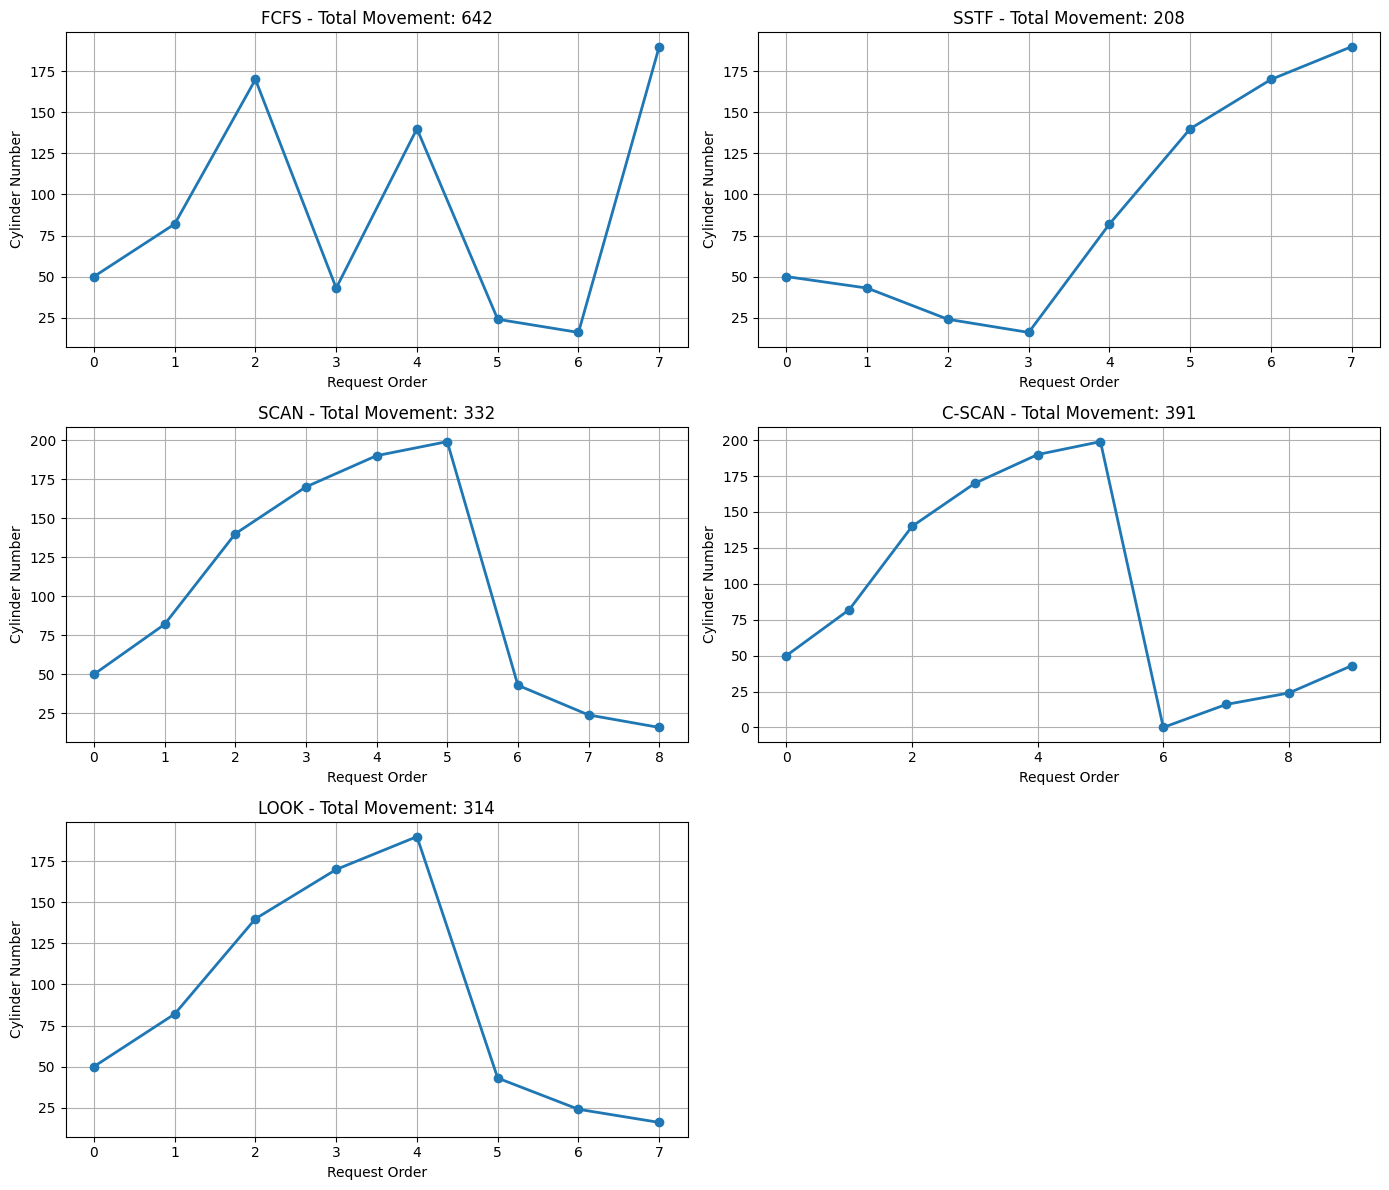

In [45]:

# Disk Scheduling Visualization

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.flatten()

for i, (name, (sequence, movement)) in enumerate(results.items()):
    ax = axes[i]

    ax.plot(
        range(len(sequence)),
        sequence,
        marker='o',
        linewidth=2
    )

    ax.set_title(f"{name} - Total Movement: {movement}")
    ax.set_xlabel("Request Order")
    ax.set_ylabel("Cylinder Number")
    ax.grid(True)

axes[5].axis("off")

plt.tight_layout()
plt.show()


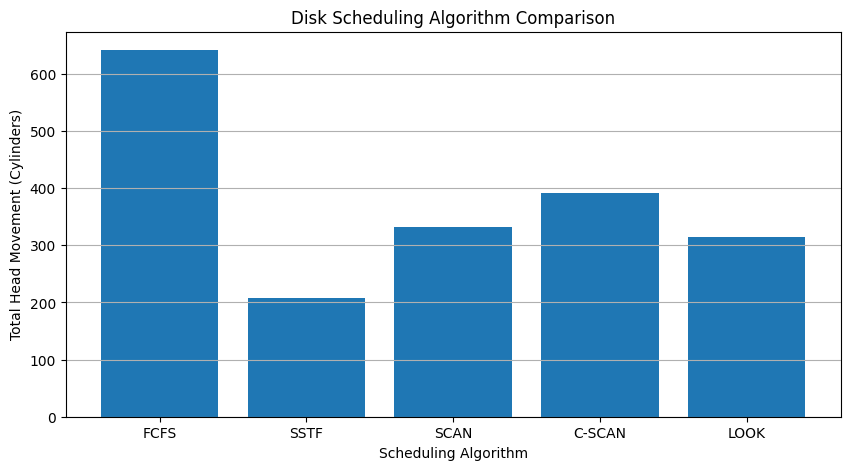

Best result for this input: SSTF


In [46]:

# Comparison Bar Chart

algorithm_names = list(results.keys())

movements = [
    results[name][1]
    for name in algorithm_names
]

plt.figure(figsize=(10, 5))

plt.bar(algorithm_names, movements)

plt.title("Disk Scheduling Algorithm Comparison")
plt.xlabel("Scheduling Algorithm")
plt.ylabel("Total Head Movement (Cylinders)")

plt.grid(axis="y")
plt.show()

print("Best result for this input:",
      min(results, key=lambda x: results[x][1]))



In [47]:

from collections import deque

# CPU FCFS Scheduling
def cpu_fcfs(processes):
    processes = sorted(processes, key=lambda p: p["arrival"])
    time_now = 0
    results = []
    gantt = []

    for p in processes:
        if time_now < p["arrival"]:
            gantt.append(("Idle", time_now, p["arrival"]))
            time_now = p["arrival"]

        start = time_now
        time_now += p["burst"]
        completion = time_now

        turnaround = completion - p["arrival"]
        waiting = turnaround - p["burst"]

        results.append({
            "PID": p["pid"],
            "Arrival": p["arrival"],
            "Burst": p["burst"],
            "Completion": completion,
            "Waiting": waiting,
            "Turnaround": turnaround
        })

        gantt.append((p["pid"], start, time_now))

    return results, gantt


# CPU Round Robin Scheduling
def cpu_round_robin(processes, quantum):
    processes = sorted(processes, key=lambda p: p["arrival"])

    remaining = {p["pid"]: p["burst"] for p in processes}
    completion = {}

    ready_queue = deque()
    gantt = []

    time_now = 0
    index = 0
    n = len(processes)

    while len(completion) < n:

        while index < n and processes[index]["arrival"] <= time_now:
            ready_queue.append(processes[index]["pid"])
            index += 1

        if not ready_queue:
            next_arrival = processes[index]["arrival"]
            if time_now < next_arrival:
                gantt.append(("Idle", time_now, next_arrival))
            time_now = next_arrival
            continue

        pid = ready_queue.popleft()

        start = time_now
        execution = min(quantum, remaining[pid])

        time_now += execution
        remaining[pid] -= execution

        gantt.append((pid, start, time_now))

        while index < n and processes[index]["arrival"] <= time_now:
            ready_queue.append(processes[index]["pid"])
            index += 1

        if remaining[pid] > 0:
            ready_queue.append(pid)
        else:
            completion[pid] = time_now

    results = []

    for p in processes:
        tat = completion[p["pid"]] - p["arrival"]
        wt = tat - p["burst"]

        results.append({
            "PID": p["pid"],
            "Arrival": p["arrival"],
            "Burst": p["burst"],
            "Completion": completion[p["pid"]],
            "Waiting": wt,
            "Turnaround": tat
        })

    return results, gantt


print("CPU FCFS and Round Robin algorithms ready!")


CPU FCFS and Round Robin algorithms ready!


In [48]:

# Sample CPU process input

processes = [
    {"pid": "P1", "arrival": 0, "burst": 5},
    {"pid": "P2", "arrival": 1, "burst": 3},
    {"pid": "P3", "arrival": 2, "burst": 8},
    {"pid": "P4", "arrival": 3, "burst": 6}
]

# Run FCFS
fcfs_results, fcfs_gantt = cpu_fcfs(processes)

# Run Round Robin with time quantum 2
rr_results, rr_gantt = cpu_round_robin(processes, 2)

print("FCFS RESULTS")
display(pd.DataFrame(fcfs_results))

print("ROUND ROBIN RESULTS")
display(pd.DataFrame(rr_results))


FCFS RESULTS


,PID,Arrival,Burst,Completion,Waiting,Turnaround
0,P1,0,5,5,0,5
1,P2,1,3,8,4,7
2,P3,2,8,16,6,14
3,P4,3,6,22,13,19


ROUND ROBIN RESULTS


,PID,Arrival,Burst,Completion,Waiting,Turnaround
0,P1,0,5,14,9,14
1,P2,1,3,11,7,10
2,P3,2,8,22,12,20
3,P4,3,6,20,11,17


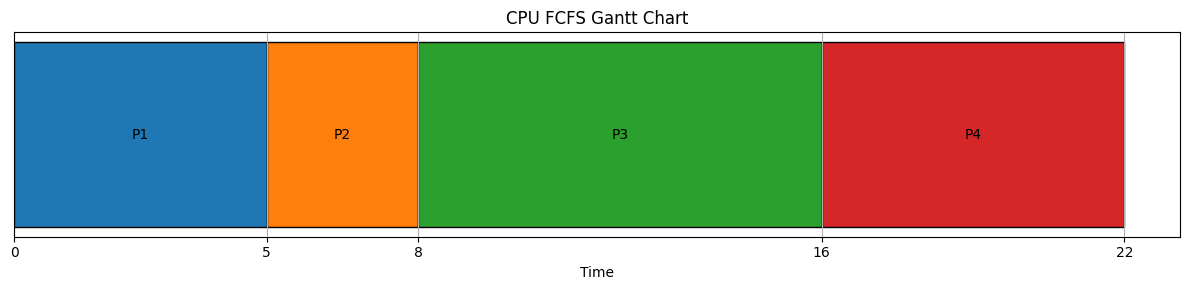

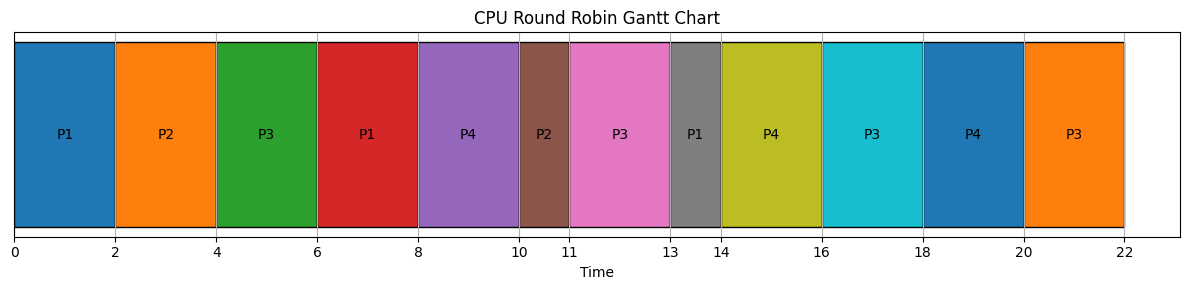

In [49]:

def draw_gantt(gantt, title):
    fig, ax = plt.subplots(figsize=(12, 3))

    for pid, start, end in gantt:
        ax.barh(
            0,
            end - start,
            left=start,
            height=0.5,
            edgecolor="black"
        )

        ax.text(
            (start + end) / 2,
            0,
            pid,
            ha="center",
            va="center"
        )

    ax.set_title(title)
    ax.set_xlabel("Time")
    ax.set_yticks([])
    ax.set_xticks(sorted(set(
        [gantt[0][1]] + [x[2] for x in gantt]
    )))
    ax.grid(axis="x")

    plt.tight_layout()
    plt.show()


draw_gantt(fcfs_gantt, "CPU FCFS Gantt Chart")
draw_gantt(rr_gantt, "CPU Round Robin Gantt Chart")


In [50]:

# Calculate CPU scheduling averages

def show_averages(results, algorithm):
    df = pd.DataFrame(results)

    avg_waiting = df["Waiting"].mean()
    avg_turnaround = df["Turnaround"].mean()

    print("\n", algorithm)
    print("Average Waiting Time:", round(avg_waiting, 2))
    print("Average Turnaround Time:", round(avg_turnaround, 2))


show_averages(fcfs_results, "FCFS")
show_averages(rr_results, "Round Robin")



 FCFS
Average Waiting Time: 5.75
Average Turnaround Time: 11.25

 Round Robin
Average Waiting Time: 9.75
Average Turnaround Time: 15.25


In [51]:

# =========================================================
# PART A: INTERACTIVE DISK SCHEDULING VISUALIZER
# =========================================================

import ipywidgets as widgets
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, clear_output
from collections import deque

# ---------- Disk Scheduling Algorithms ----------

def movement(sequence):
    return sum(abs(sequence[i] - sequence[i-1])
               for i in range(1, len(sequence)))


def disk_fcfs(requests, head):
    seq = [head] + requests
    return seq, movement(seq)


def disk_sstf(requests, head):
    remaining = requests.copy()
    seq = [head]
    current = head

    while remaining:
        index = min(
            range(len(remaining)),
            key=lambda i: abs(remaining[i] - current)
        )
        current = remaining.pop(index)
        seq.append(current)

    return seq, movement(seq)


def disk_scan(requests, head, size, direction):
    left = sorted([r for r in requests if r < head], reverse=True)
    right = sorted([r for r in requests if r >= head])

    seq = [head]

    if direction == "Right":
        seq += right
        if left:
            if seq[-1] != size - 1:
                seq.append(size - 1)
            seq += left
    else:
        seq += left
        if right:
            if seq[-1] != 0:
                seq.append(0)
            seq += right

    return seq, movement(seq)


def disk_cscan(requests, head, size, direction):
    left = sorted([r for r in requests if r < head])
    right = sorted([r for r in requests if r >= head])

    seq = [head]

    if direction == "Right":
        seq += right
        if left:
            if seq[-1] != size - 1:
                seq.append(size - 1)
            seq.append(0)
            seq += left
    else:
        seq += left[::-1]
        if right:
            if seq[-1] != 0:
                seq.append(0)
            seq.append(size - 1)
            seq += right[::-1]

    return seq, movement(seq)


def disk_look(requests, head, direction):
    left = sorted([r for r in requests if r < head], reverse=True)
    right = sorted([r for r in requests if r >= head])

    seq = [head]

    if direction == "Right":
        seq += right + left
    else:
        seq += left + right

    return seq, movement(seq)


# ---------- User Input Controls ----------

disk_size_input = widgets.IntText(
    value=200, description="Disk size:",
    style={"description_width": "initial"}
)

head_input = widgets.IntText(
    value=50, description="Initial head:",
    style={"description_width": "initial"}
)

requests_input = widgets.Text(
    value="82,170,43,140,24,16,190",
    description="Requests:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="95%")
)

direction_input = widgets.Dropdown(
    options=["Right", "Left"],
    value="Right",
    description="Direction:"
)

algorithm_input = widgets.Dropdown(
    options=["FCFS", "SSTF", "SCAN", "C-SCAN", "LOOK"],
    value="FCFS",
    description="Algorithm:"
)

run_disk_button = widgets.Button(
    description="Run Disk Scheduling",
    button_style="success",
    icon="play"
)

disk_output = widgets.Output()


# ---------- Result Storage ----------

disk_sequence = []
current_algorithm = ""
total_movement = 0


def calculate_disk(b):
    global disk_sequence, current_algorithm, total_movement

    with disk_output:
        clear_output(wait=True)

        try:
            size = disk_size_input.value
            head = head_input.value
            requests = [
                int(x.strip())
                for x in requests_input.value.split(",")
                if x.strip()
            ]

            direction = direction_input.value
            algorithm = algorithm_input.value

            if size < 1:
                raise ValueError("Disk size must be positive.")

            if not (0 <= head < size):
                raise ValueError("Initial head must be within disk range.")

            if not requests:
                raise ValueError("Enter at least one request.")

            if any(r < 0 or r >= size for r in requests):
                raise ValueError(
                    f"All requests must be between 0 and {size-1}."
                )

            if algorithm == "FCFS":
                seq, total = disk_fcfs(requests, head)

            elif algorithm == "SSTF":
                seq, total = disk_sstf(requests, head)

            elif algorithm == "SCAN":
                seq, total = disk_scan(
                    requests, head, size, direction
                )

            elif algorithm == "C-SCAN":
                seq, total = disk_cscan(
                    requests, head, size, direction
                )

            else:
                seq, total = disk_look(
                    requests, head, direction
                )

            disk_sequence = seq
            current_algorithm = algorithm
            total_movement = total

            print("Algorithm:", algorithm)
            print("Head movement sequence:", " -> ".join(map(str, seq)))
            print("Total head movement:", total, "cylinders")

            # Comparison of all algorithms using same input
            all_results = {
                "FCFS": disk_fcfs(requests, head),
                "SSTF": disk_sstf(requests, head),
                "SCAN": disk_scan(requests, head, size, direction),
                "C-SCAN": disk_cscan(requests, head, size, direction),
                "LOOK": disk_look(requests, head, direction)
            }

            comparison = pd.DataFrame([
                {"Algorithm": name, "Head Movement": result[1]}
                for name, result in all_results.items()
            ])

            display(comparison)

            plt.figure(figsize=(9, 4))
            plt.bar(comparison["Algorithm"],
                    comparison["Head Movement"])
            plt.title("Disk Scheduling Comparison")
            plt.ylabel("Total Head Movement (Cylinders)")
            plt.grid(axis="y")
            plt.show()

            # Reset animation position
            step_slider.max = len(seq) - 1
            step_slider.value = 0

        except Exception as e:
            print("Input Error:", e)


run_disk_button.on_click(calculate_disk)


# ---------- Step-by-Step Animation ----------

step_slider = widgets.IntSlider(
    value=0, min=0, max=0,
    description="Step:",
    continuous_update=False
)

play_button = widgets.Play(
    value=0,
    min=0,
    max=0,
    step=1,
    interval=900,
    description="Auto Play"
)

widgets.jslink((play_button, "value"), (step_slider, "value"))

previous_button = widgets.Button(
    description="Previous",
    icon="backward"
)

next_button = widgets.Button(
    description="Next",
    icon="forward"
)

animation_output = widgets.Output()


def draw_disk_step(change=None):
    with animation_output:
        clear_output(wait=True)

        if not disk_sequence:
            print("Run an algorithm first.")
            return

        step = step_slider.value
        visible = disk_sequence[:step + 1]

        print("Algorithm:", current_algorithm)
        print("Current step:", step, "/", len(disk_sequence)-1)
        print("Visited cylinders:", visible)

        if step > 0:
            print(
                "Movement in this step:",
                abs(disk_sequence[step] - disk_sequence[step-1])
            )

        print("Total movement so far:", movement(visible))

        plt.figure(figsize=(10, 4))
        plt.plot(
            range(len(visible)),
            visible,
            marker="o",
            linewidth=2
        )

        plt.xticks(range(len(visible)))
        plt.xlabel("Step")
        plt.ylabel("Cylinder")
        plt.title("Disk Head Movement Animation")
        plt.grid(True)
        plt.show()


def previous_step(b):
    step_slider.value = max(0, step_slider.value - 1)


def next_step(b):
    step_slider.value = min(
        step_slider.max, step_slider.value + 1
    )


previous_button.on_click(previous_step)
next_button.on_click(next_step)
step_slider.observe(draw_disk_step, names="value")


# ---------- Display Interface ----------

display(widgets.HTML(
    "<h2>OS Scheduling Visualizer - Disk Scheduling</h2>"
))

display(widgets.VBox([
    disk_size_input,
    head_input,
    requests_input,
    direction_input,
    algorithm_input,
    run_disk_button,
    disk_output,
    widgets.HTML("<h3>Step-by-Step Animation</h3>"),
    widgets.HBox([previous_button, next_button, play_button]),
    step_slider,
    animation_output
]))


HTML(value='<h2>OS Scheduling Visualizer - Disk Scheduling</h2>')

In [52]:

# =========================================================
# PART B: INTERACTIVE CPU SCHEDULING VISUALIZER
# =========================================================

# ---------- FCFS CPU Scheduling ----------

def run_cpu_fcfs(processes):
    ordered = sorted(processes, key=lambda p: (p["arrival"], p["order"]))

    time_now = 0
    results = []
    gantt = []

    for p in ordered:
        if time_now < p["arrival"]:
            gantt.append(("Idle", time_now, p["arrival"]))
            time_now = p["arrival"]

        start = time_now
        time_now += p["burst"]

        turnaround = time_now - p["arrival"]
        waiting = turnaround - p["burst"]

        results.append({
            "PID": p["pid"],
            "Arrival": p["arrival"],
            "Burst": p["burst"],
            "Completion": time_now,
            "Waiting": waiting,
            "Turnaround": turnaround
        })

        gantt.append((p["pid"], start, time_now))

    return results, gantt


# ---------- Round Robin CPU Scheduling ----------

def run_cpu_rr(processes, quantum):
    ordered = sorted(processes, key=lambda p: (p["arrival"], p["order"]))

    remaining = {p["pid"]: p["burst"] for p in ordered}
    completion = {}

    ready = deque()
    gantt = []

    time_now = 0
    index = 0

    while len(completion) < len(ordered):

        while index < len(ordered) and ordered[index]["arrival"] <= time_now:
            ready.append(ordered[index]["pid"])
            index += 1

        if not ready:
            next_time = ordered[index]["arrival"]
            if next_time > time_now:
                gantt.append(("Idle", time_now, next_time))
            time_now = next_time
            continue

        pid = ready.popleft()

        start = time_now
        run_time = min(quantum, remaining[pid])

        time_now += run_time
        remaining[pid] -= run_time

        gantt.append((pid, start, time_now))

        # Add newly arrived processes before re-queuing current process
        while index < len(ordered) and ordered[index]["arrival"] <= time_now:
            ready.append(ordered[index]["pid"])
            index += 1

        if remaining[pid] > 0:
            ready.append(pid)
        else:
            completion[pid] = time_now

    results = []

    for p in ordered:
        tat = completion[p["pid"]] - p["arrival"]
        wt = tat - p["burst"]

        results.append({
            "PID": p["pid"],
            "Arrival": p["arrival"],
            "Burst": p["burst"],
            "Completion": completion[p["pid"]],
            "Waiting": wt,
            "Turnaround": tat
        })

    return results, gantt


# ---------- Interactive CPU Inputs ----------

cpu_process_input = widgets.Textarea(
    value="P1,0,5\nP2,1,3\nP3,2,8\nP4,3,6",
    description="Processes:",
    placeholder="PID, Arrival, Burst",
    layout=widgets.Layout(width="95%", height="130px"),
    style={"description_width": "initial"}
)

quantum_input = widgets.IntText(
    value=2,
    description="Time Quantum:",
    style={"description_width": "initial"}
)

cpu_algorithm_input = widgets.Dropdown(
    options=["FCFS", "Round Robin"],
    value="FCFS",
    description="Algorithm:"
)

run_cpu_button = widgets.Button(
    description="Run CPU Scheduling",
    button_style="success",
    icon="play"
)

cpu_output = widgets.Output()


# ---------- Gantt Chart ----------

def plot_cpu_gantt(gantt, title):
    if not gantt:
        return

    fig, ax = plt.subplots(figsize=(12, 3))

    for pid, start, end in gantt:
        ax.barh(
            0,
            end - start,
            left=start,
            height=0.5,
            edgecolor="black"
        )

        ax.text(
            (start + end) / 2,
            0,
            pid,
            ha="center",
            va="center"
        )

    ax.set_title(title)
    ax.set_xlabel("CPU Time")
    ax.set_yticks([])

    ticks = sorted(set(
        [gantt[0][1]] + [item[2] for item in gantt]
    ))

    ax.set_xticks(ticks)
    ax.grid(axis="x")
    plt.tight_layout()
    plt.show()


# ---------- Run CPU Scheduling ----------

def calculate_cpu(b):
    with cpu_output:
        clear_output(wait=True)

        try:
            lines = cpu_process_input.value.strip().splitlines()

            if not lines or not cpu_process_input.value.strip():
                raise ValueError("Enter at least one process.")

            processes = []
            used_ids = set()

            for i, line in enumerate(lines):
                parts = [x.strip() for x in line.split(",")]

                if len(parts) != 3:
                    raise ValueError(
                        f"Line {i+1}: Use PID, Arrival, Burst."
                    )

                pid = parts[0]

                if not pid:
                    raise ValueError("Process ID cannot be empty.")

                if pid in used_ids:
                    raise ValueError(f"Duplicate process ID: {pid}")

                arrival = int(parts[1])
                burst = int(parts[2])

                if arrival < 0:
                    raise ValueError("Arrival time cannot be negative.")

                if burst <= 0:
                    raise ValueError("Burst time must be positive.")

                used_ids.add(pid)

                processes.append({
                    "pid": pid,
                    "arrival": arrival,
                    "burst": burst,
                    "order": i
                })

            if cpu_algorithm_input.value == "FCFS":
                results, gantt = run_cpu_fcfs(processes)
                algorithm_name = "FCFS"

            else:
                quantum = quantum_input.value

                if quantum <= 0:
                    raise ValueError("Time quantum must be positive.")

                results, gantt = run_cpu_rr(processes, quantum)
                algorithm_name = "Round Robin"

            df = pd.DataFrame(results)

            print("CPU Scheduling:", algorithm_name)
            print("\nProcess Scheduling Results:")
            display(df)

            print("Average Waiting Time:",
                  round(df["Waiting"].mean(), 2))

            print("Average Turnaround Time:",
                  round(df["Turnaround"].mean(), 2))

            print("\nCPU Gantt Chart:")
            plot_cpu_gantt(gantt, algorithm_name + " Gantt Chart")

        except Exception as e:
            print("Input Error:", e)


run_cpu_button.on_click(calculate_cpu)


display(widgets.HTML(
    "<h2>OS Scheduling Visualizer - CPU Scheduling</h2>"
))

display(widgets.HTML(
    "<b>Enter one process per line: PID, Arrival Time, Burst Time</b>"
))

display(widgets.VBox([
    cpu_process_input,
    cpu_algorithm_input,
    quantum_input,
    run_cpu_button,
    cpu_output
]))


HTML(value='<h2>OS Scheduling Visualizer - CPU Scheduling</h2>')

HTML(value='<b>Enter one process per line: PID, Arrival Time, Burst Time</b>')